# Exploratory Data Analysis (EDA): Drug–Drug Interactions Dataset

**Dataset file:** `db_drug_interactions.csv`

**Goal of this notebook:** understand the structure and quality of the dataset, clean it, explore it with tables and charts, and write down the main insights.

**About this dataset (from what we can see in the file):** each row describes one interaction between two drugs (`Drug 1` and `Drug 2`) with a sentence explaining the effect (`Interaction Description`). All 3 columns are **text**. There are no original numeric or date columns, so in this project we create a few simple numeric/category columns from the text to be able to do statistics and charts.

**Tools used:** pandas, numpy, matplotlib, seaborn only. No machine learning and no SQL in this notebook.

> **Put `db_drug_interactions.csv` in the same folder as this notebook before running it.**

# 1. Import Libraries

We start by importing the libraries we need.

- `pandas` for tables (DataFrames)
- `numpy` for simple numeric work
- `matplotlib` and `seaborn` for charts
- `os` only to check that our saved file exists at the end

**Expected output:** nothing is printed. If there is no error, the libraries are ready.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Make all charts look clean
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

# 2. Load Dataset

We load the CSV file into a DataFrame called `df`, then look at:

- the first 5 rows (`head`)
- the last 5 rows (`tail`)
- the number of rows and columns (`shape`)
- the column names (`columns`)
- the data types and non-null counts (`info`)

**Expected output:** a table of 5 rows, another table of 5 rows, a pair of numbers like `(rows, columns)`, a list of names, and a summary of the columns.

In [2]:
# Load the dataset
df = pd.read_csv("db_drug_interactions.csv")

# Keep the original number of rows so we can compare after cleaning
rows_before = df.shape[0]

# First 5 rows
df.head()

,Drug 1,Drug 2,Interaction Description
0,Trioxsalen,Verteporfin,Trioxsalen may increase the photosensitizing a...
1,Aminolevulinic acid,Verteporfin,Aminolevulinic acid may increase the photosens...
2,Titanium dioxide,Verteporfin,Titanium dioxide may increase the photosensiti...
3,Tiaprofenic acid,Verteporfin,Tiaprofenic acid may increase the photosensiti...
4,Cyamemazine,Verteporfin,Cyamemazine may increase the photosensitizing ...


**What does this show?** Each row is one pair of drugs and one sentence that explains how they interact. For example, the first rows say that some drug *may increase the photosensitizing activities of Verteporfin*. The drug names are also written inside the sentence.

In [3]:
# Last 5 rows
df.tail()

,Drug 1,Drug 2,Interaction Description
191536,Ascorbic acid,Deferoxamine,The risk or severity of adverse effects can be...
191537,Tenofovir disoproxil,Cidofovir,Tenofovir disoproxil may decrease the excretio...
191538,Tenofovir disoproxil,Ganciclovir,The serum concentration of Ganciclovir can be ...
191539,Tenofovir disoproxil,Valganciclovir,The serum concentration of Valganciclovir can ...
191540,L-Glutamine,Lactulose,The therapeutic efficacy of Lactulose can be d...


**What does this show?** The end of the file has the same 3 columns and the same style of sentences, so the file looks consistent from top to bottom.

In [4]:
# Number of rows and columns
print("Shape (rows, columns):", df.shape)
print("Number of rows   :", df.shape[0])
print("Number of columns:", df.shape[1])

Shape (rows, columns): (191541, 3)
Number of rows   : 191541
Number of columns: 3


In [5]:
# Column names
print(df.columns.tolist())

['Drug 1', 'Drug 2', 'Interaction Description']


In [6]:
# Data types and non-null counts
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 191541 entries, 0 to 191540
Data columns (total 3 columns):
 #   Column                   Non-Null Count   Dtype
---  ------                   --------------   -----
 0   Drug 1                   191541 non-null  str  
 1   Drug 2                   191541 non-null  str  
 2   Interaction Description  191541 non-null  str  
dtypes: str(3)
memory usage: 4.4 MB


**What do these outputs tell us?**

- The dataset has **191,541 rows** and **3 columns**: `Drug 1`, `Drug 2`, and `Interaction Description`.
- All 3 columns are text (pandas shows them as `object`, or `str` in newer pandas versions).
- `df.info()` shows that every column has 191,541 non-null values, so there are no missing values (we double-check this in Section 4).

# 3. Understand the Dataset

Here we separate the columns into numerical and categorical (text) columns and explain what each column means.

**Expected output:** the number of rows and columns, then two lists of column names.

In [7]:
print("Number of rows   :", df.shape[0])
print("Number of columns:", df.shape[1])
print()

# Numerical columns (numbers)
numeric_columns = df.select_dtypes(include="number").columns.tolist()

# All other columns (text / categorical)
text_columns = df.select_dtypes(exclude="number").columns.tolist()

print("Numerical columns :", numeric_columns)
print("Text (categorical) columns:", text_columns)

Number of rows   : 191541
Number of columns: 3

Numerical columns : []
Text (categorical) columns: ['Drug 1', 'Drug 2', 'Interaction Description']


**What does this mean?** The original dataset has **no numerical columns**. All 3 columns are text.

**Meaning of the columns (based only on the real data):**

| Column | Meaning |
|---|---|
| `Drug 1` | The name of the first drug in the pair. |
| `Drug 2` | The name of the second drug in the pair. |
| `Interaction Description` | One sentence that explains the effect of combining the two drugs (for example, the risk of side effects can be increased, or the serum concentration can be decreased). |

Because there are no numeric columns, in Section 7 we will **create 4 simple new columns from the description text**:

- `Description Length`: number of characters in the sentence (numeric)
- `Word Count`: number of words in the sentence (numeric)
- `Interaction Type`: what the interaction is about (for example Metabolism, Serum Concentration)
- `Effect`: whether the sentence says the effect is increased or decreased

# 4. Missing Values

Missing values are empty cells. We count them in every column and also show the percentage.

**Expected output:** a table with one row per column showing the count and percentage of missing values.

In [8]:
# Number of missing values in each column
missing_count = df.isnull().sum()

# Percentage of missing values in each column
missing_percent = (df.isnull().sum() / len(df)) * 100

# Put both together in one small table
missing_table = pd.DataFrame({
    "Missing Count": missing_count,
    "Missing Percent (%)": missing_percent.round(2)
})

missing_table

,Missing Count,Missing Percent (%)
Drug 1,0,0.0
Drug 2,0,0.0
Interaction Description,0,0.0


**What does this mean?** None of the 3 columns has missing values (0 missing, 0%). So **no handling is needed**: we do not need to drop rows or fill any value.

# 5. Duplicate Values

A duplicate row is a row that is exactly the same as another row in all columns. We check for them and remove them if they exist.

We also do two extra checks that make sense for this dataset:

1. Are there rows with the **same `Drug 1` and `Drug 2`** but a different sentence?
2. Are there pairs that appear **in both directions** (A with B, and also B with A)?

**Expected output:** a number for exact duplicates, then a number for repeated drug pairs.

In [9]:
# 1) Exact duplicate rows
print("Exact duplicate rows:", df.duplicated().sum())

# Remove them (if there are none, nothing changes)
df = df.drop_duplicates()

# Verify
print("Duplicates after removing:", df.duplicated().sum())
print("Rows now:", df.shape[0])

Exact duplicate rows: 0


Duplicates after removing: 0
Rows now: 191541


In [10]:
# 2) Same Drug 1 + Drug 2 appearing more than once (with a different sentence)
repeated_pairs = df.duplicated(subset=["Drug 1", "Drug 2"]).sum()
print("Rows that repeat an existing Drug 1 + Drug 2 pair:", repeated_pairs)

# Show a few examples
same_pair = df[df.duplicated(subset=["Drug 1", "Drug 2"], keep=False)]
same_pair.sort_values(["Drug 1", "Drug 2"]).head(6)

Rows that repeat an existing Drug 1 + Drug 2 pair: 289


,Drug 1,Drug 2,Interaction Description
77615,Amodiaquine,Celecoxib,The metabolism of Celecoxib can be decreased w...
77616,Amodiaquine,Celecoxib,The serum concentration of Celecoxib can be in...
26455,Amodiaquine,Clotrimazole,The metabolism of Clotrimazole can be decrease...
26456,Amodiaquine,Clotrimazole,The serum concentration of Clotrimazole can be...
85213,Amodiaquine,Crisaborole,The metabolism of Crisaborole can be decreased...
85214,Amodiaquine,Crisaborole,The serum concentration of Crisaborole can be ...


In [11]:
# 3) Pairs that appear in both directions (A-B and also B-A)
pairs = set(zip(df["Drug 1"], df["Drug 2"]))

reversed_count = 0
for first, second in pairs:
    if (second, first) in pairs:
        reversed_count = reversed_count + 1

# Each reversed pair is counted twice (once in each direction), so we divide by 2
print("Drug pairs that appear in both orders (A-B and B-A):", reversed_count // 2)

Drug pairs that appear in both orders (A-B and B-A): 117


**What does this mean?**

- There are **0 exact duplicate rows**, so nothing was removed.
- Some rows have the same `Drug 1` and `Drug 2` but a **different sentence**. Looking at the examples, they describe *different effects* of the same pair (for example one row about metabolism and another about serum concentration). These are not real duplicates, so we **keep them**.
- **117 drug pairs** also appear in reverse order (A–B and B–A). Their sentences can be different, so we **keep them** too. We just remember this when we count interactions per drug.

# 6. Data Types

We check whether the columns have the right data types.

- **Numerical columns:** the original dataset has none, so there is nothing to convert with `pd.to_numeric`.
- **Date columns:** the dataset has no date column, so `pd.to_datetime` is not needed.

**Expected output:** a list of data types, and a short message.

In [12]:
# Data type of every column
df.dtypes

Drug 1                     str
Drug 2                     str
Interaction Description    str
dtype: object

In [13]:
# Are there any numeric or date columns in the original data?
print("Numeric columns in original data:", df.select_dtypes(include="number").columns.tolist())
print("Date columns in original data   : none (no column has date values)")

Numeric columns in original data: []
Date columns in original data   : none (no column has date values)


**What does this mean?** All 3 columns are text and text is the correct type for drug names and sentences. No type conversion is necessary.

*Numeric-type conversion and date conversion: This analysis is not applicable because the dataset does not contain the required type of variable.*

# 7. Data Cleaning

In this section we:

1. Remove extra spaces from the text columns.
2. Check capitalization and inconsistent values.
3. Create new simple columns from the description text.

**Expected output:** counts of text problems, then a preview of the new columns.

### 7.1 Extra spaces

In [14]:
# Count how many values have spaces at the start or end
for column in ["Drug 1", "Drug 2", "Interaction Description"]:
    with_spaces = (df[column] != df[column].str.strip()).sum()
    print(column, "-> values with extra spaces:", with_spaces)

# Apply strip anyway (safe: it does nothing if there are no extra spaces)
df["Drug 1"] = df["Drug 1"].str.strip()
df["Drug 2"] = df["Drug 2"].str.strip()
df["Interaction Description"] = df["Interaction Description"].str.strip()

Drug 1 -> values with extra spaces: 0
Drug 2 -> values with extra spaces: 0
Interaction Description -> values with extra spaces: 0


**Result:** no column has extra spaces at the start or end.

### 7.2 Capitalization and inconsistent values

In [15]:
# Do any drug names start with a lowercase letter?
for column in ["Drug 1", "Drug 2"]:
    starts_lower = df[df[column].str[0].str.islower()]
    print(column, "-> names starting with lowercase:", starts_lower[column].unique())

Drug 1 -> names starting with lowercase: <StringArray>
['gamma-Hydroxybutyric acid']
Length: 1, dtype: str
Drug 2 -> names starting with lowercase: <StringArray>
['gamma-Hydroxybutyric acid']
Length: 1, dtype: str


**Result and decision:** almost all drug names already start with a capital letter. The only exception is `gamma-Hydroxybutyric acid`, which is the correct chemical spelling. If we used `.str.title()` or `.str.upper()` on the drug names we would **damage** names like this one, so we **do not change the capitalization**.

### 7.3 Create new columns from the description

The description sentences follow a small number of patterns, such as *"The serum concentration of X can be increased when..."* or *"The risk or severity of adverse effects can be increased when..."*. We use simple keyword searches to create:

- `Description Length` and `Word Count` (numeric)
- `Interaction Type` (category)
- `Effect` (Increase or Decrease)

**Note:** these columns are our own simple keyword-based labels, not original data. Each row gets **one** type; when several keywords appear, the one written **last** in the code wins.

In [16]:
# --- Numeric columns ---
df["Description Length"] = df["Interaction Description"].str.len()
df["Word Count"] = df["Interaction Description"].str.split().str.len()

# --- Interaction Type ---
# Start with "Other", then replace using keywords
df["Interaction Type"] = "Other"

df.loc[df["Interaction Description"].str.contains("serum concentration", case=False), "Interaction Type"] = "Serum Concentration"
df.loc[df["Interaction Description"].str.contains("metabolism", case=False), "Interaction Type"] = "Metabolism"
df.loc[df["Interaction Description"].str.contains("excretion", case=False), "Interaction Type"] = "Excretion"
df.loc[df["Interaction Description"].str.contains("absorption", case=False), "Interaction Type"] = "Absorption"
df.loc[df["Interaction Description"].str.contains("therapeutic efficacy", case=False), "Interaction Type"] = "Therapeutic Efficacy"
df.loc[df["Interaction Description"].str.contains("risk or severity", case=False), "Interaction Type"] = "Risk / Severity of Adverse Effects"
df.loc[df["Interaction Description"].str.contains("activities", case=False), "Interaction Type"] = "Pharmacodynamic Activity"

# --- Effect (Increase or Decrease) ---
# Decrease first, then Increase (if a sentence has both words, it is labelled Increase)
df["Effect"] = "Other"
df.loc[df["Interaction Description"].str.contains("decrease|reduc", case=False), "Effect"] = "Decrease"
df.loc[df["Interaction Description"].str.contains("increase", case=False), "Effect"] = "Increase"

df[["Interaction Description", "Description Length", "Word Count", "Interaction Type", "Effect"]].head()

,Interaction Description,Description Length,Word Count,Interaction Type,Effect
0,Trioxsalen may increase the photosensitizing a...,71,8,Pharmacodynamic Activity,Increase
1,Aminolevulinic acid may increase the photosens...,80,9,Pharmacodynamic Activity,Increase
2,Titanium dioxide may increase the photosensiti...,77,9,Pharmacodynamic Activity,Increase
3,Tiaprofenic acid may increase the photosensiti...,77,9,Pharmacodynamic Activity,Increase
4,Cyamemazine may increase the photosensitizing ...,72,8,Pharmacodynamic Activity,Increase


In [17]:
# Check the new columns
print(df["Interaction Type"].value_counts())
print()
print(df["Effect"].value_counts())

Interaction Type
Risk / Severity of Adverse Effects    61370
Pharmacodynamic Activity              45339
Metabolism                            39313
Serum Concentration                   34019
Therapeutic Efficacy                   8024
Excretion                              1856
Absorption                             1020
Other                                   600
Name: count, dtype: int64

Effect
Increase    129882
Decrease     61659
Name: count, dtype: int64


**What does this mean?**

- Every sentence got a label. Only a very small group (about 0.3%) is `Other` (for example sentences about *bioavailability*).
- Every sentence is either `Increase` or `Decrease`, so the `Effect` column has no `Other` values.
- We now have 2 numeric columns and 2 category columns that we can use in the rest of the EDA.

# 8. Descriptive Statistics

`df.describe()` gives count, mean, standard deviation, minimum, quartiles (25%, 50% = median, 75%) and maximum for numeric columns.

Because the original columns are text, the numeric statistics are for the two columns we created: `Description Length` and `Word Count`. For the text columns, `describe()` shows how many unique values there are and the most frequent one.

**Expected output:** one table for numeric columns and one table for text columns.

In [18]:
# Numeric columns
df[["Description Length", "Word Count"]].describe().round(2)

,Description Length,Word Count
count,191541.00,191541.00
mean,89.85,12.99
std,15.90,3.20
min,58.00,8.00
25%,76.00,11.00
50%,92.00,14.00
75%,102.00,16.00
max,195.00,29.00


In [19]:
# Median (same as the 50% row) and the standard deviation, printed clearly
for column in ["Description Length", "Word Count"]:
    print(column)
    print("  Mean   :", round(df[column].mean(), 2))
    print("  Median :", df[column].median())
    print("  Min    :", df[column].min())
    print("  Max    :", df[column].max())
    print("  Std    :", round(df[column].std(), 2))
    print()

Description Length
  Mean   : 89.85
  Median : 92.0
  Min    : 58
  Max    : 195
  Std    : 15.9

Word Count
  Mean   : 12.99
  Median : 14.0
  Min    : 8
  Max    : 29
  Std    : 3.2



In [20]:
# Text columns: number of unique values and most frequent value
df[["Drug 1", "Drug 2"]].describe()

,Drug 1,Drug 2
count,191541,191541
unique,1634,1606
top,Phenobarbital,Stiripentol
freq,858,736


**What does this mean? (simple language)**

- A description has on average about **90 characters** (**13 words**). The median is 92 characters, very close to the mean, so the values are fairly balanced around the middle.
- The shortest sentence has **58 characters** (8 words) and the longest has **195 characters** (29 words).
- The standard deviation is about **15.9 characters**, so most sentences are within roughly 74 to 106 characters.
- `Drug 1` has **1,634** different drugs and `Drug 2` has **1,606** different drugs. The most frequent `Drug 1` is **Phenobarbital** (858 rows) and the most frequent `Drug 2` is **Stiripentol** (736 rows).

# 9. Categorical Analysis

Now we count categories using `value_counts()` and show percentages. We analyze:

- `Interaction Type` and `Effect` (our new category columns)
- `Drug 1` and `Drug 2` (top 10 only, because there are more than 1,600 different drugs)
- All drugs together (a drug can appear as `Drug 1` or as `Drug 2`)

**Expected output:** small tables with counts and percentages.

In [21]:
# Interaction Type: counts and percentages
type_counts = df["Interaction Type"].value_counts()
type_percent = (df["Interaction Type"].value_counts(normalize=True) * 100).round(2)

pd.DataFrame({"Count": type_counts, "Percent (%)": type_percent})

,Count,Percent (%)
Interaction Type,,
Risk / Severity of Adverse Effects,61370,32.04
Pharmacodynamic Activity,45339,23.67
Metabolism,39313,20.52
Serum Concentration,34019,17.76
Therapeutic Efficacy,8024,4.19
Excretion,1856,0.97
Absorption,1020,0.53
Other,600,0.31


In [22]:
# Effect: counts and percentages
effect_counts = df["Effect"].value_counts()
effect_percent = (df["Effect"].value_counts(normalize=True) * 100).round(2)

pd.DataFrame({"Count": effect_counts, "Percent (%)": effect_percent})

,Count,Percent (%)
Effect,,
Increase,129882,67.81
Decrease,61659,32.19


In [23]:
# Top 10 drugs in the Drug 1 column and in the Drug 2 column
print("Top 10 Drug 1:")
print(df["Drug 1"].value_counts().head(10))
print()
print("Top 10 Drug 2:")
print(df["Drug 2"].value_counts().head(10))

Top 10 Drug 1:


Drug 1
Phenobarbital    858
Pentobarbital    820
Carbamazepine    800
Primidone        765
Phenytoin        752
Rifampicin       736
Fosphenytoin     734
Rifapentine      704
Rifabutin        625
Dabrafenib       615
Name: count, dtype: int64

Top 10 Drug 2:
Drug 2
Stiripentol     736
Ketoconazole    684
Fluvoxamine     677
Nefazodone      668
Clotrimazole    653
Indinavir       651
Mifepristone    648
Clemastine      646
Ticlopidine     642
Venlafaxine     639
Name: count, dtype: int64


In [24]:
# All drugs together: stack Drug 1 and Drug 2 into one long list
all_drugs = pd.concat([df["Drug 1"], df["Drug 2"]])
drug_counts = all_drugs.value_counts()

print("Number of different drugs in the dataset:", len(drug_counts))
print()
print("Top 10 most frequent drugs (Drug 1 + Drug 2):")
print(drug_counts.head(10))
print()
print("Bottom 5 drugs (least frequent):")
print(drug_counts.tail(5))

Number of different drugs in the dataset: 1701

Top 10 most frequent drugs (Drug 1 + Drug 2):
Phenobarbital    920
Primidone        896
Phenytoin        895
Fosphenytoin     877
Carbamazepine    868
Venlafaxine      860
Pentobarbital    845
Fluvoxamine      845
Amiodarone       844
Nefazodone       815
Name: count, dtype: int64

Bottom 5 drugs (least frequent):
Trimetazidine    1
Benzoctamine     1
Captodiame       1
Cloxazolam       1
Lactulose        1
Name: count, dtype: int64


**What does this mean?**

- **Most common interaction type:** *Risk / Severity of Adverse Effects* (about 32%), then *Pharmacodynamic Activity* (about 24%), *Metabolism* (about 21%) and *Serum Concentration* (about 18%). *Therapeutic Efficacy* is about 4%, and *Excretion*, *Absorption* and *Other* together are less than 2%. **Least common:** `Other` (about 0.3%).
- **Effect:** about **68%** of the sentences describe an **increase** and about **32%** a **decrease**.
- There are **1,701** different drugs in total. **Phenobarbital** appears most often (920 times), followed by Primidone, Phenytoin, Fosphenytoin and Carbamazepine.
- Some drugs appear only **once** (for example Lactulose, Cloxazolam, Trimetazidine).

# 10. Univariate Analysis

Univariate analysis means looking at **one variable at a time**.

- Numeric columns: histogram and boxplot
- Categorical columns: bar chart

We choose only the important variables.

### 10.1 Description Length (numeric)

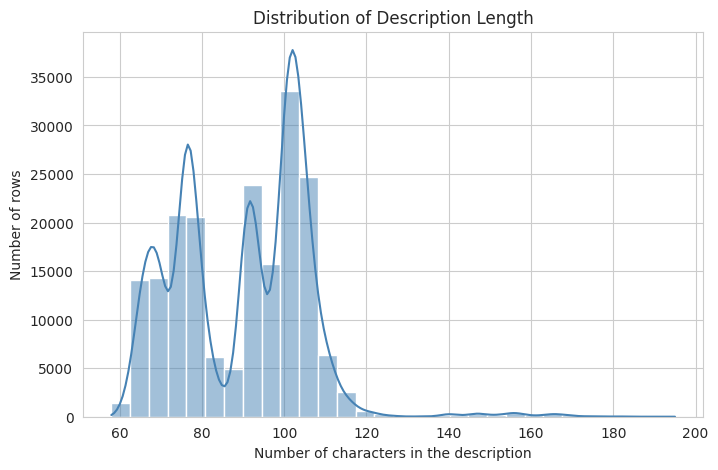

In [25]:
plt.figure(figsize=(8, 5))
sns.histplot(df["Description Length"], bins=30, kde=True, color="steelblue")
plt.title("Distribution of Description Length")
plt.xlabel("Number of characters in the description")
plt.ylabel("Number of rows")
plt.show()

**What does this chart show?** Most descriptions are between about 70 and 105 characters. The chart has several separate bumps because the dataset uses a few different sentence templates (short ones like *"X may increase the ... activities of Y"* and longer ones like *"The risk or severity of adverse effects can be increased when..."*). There is a small tail of very long sentences on the right.

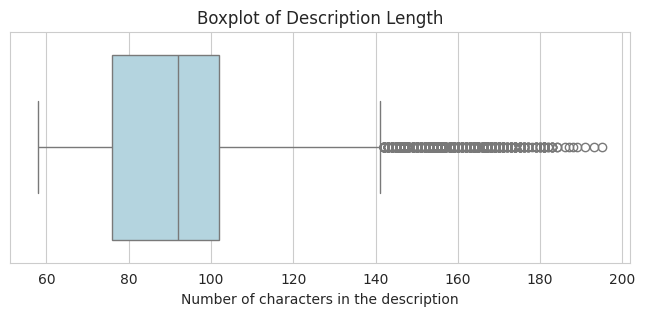

In [26]:
plt.figure(figsize=(8, 3))
sns.boxplot(x=df["Description Length"], color="lightblue")
plt.title("Boxplot of Description Length")
plt.xlabel("Number of characters in the description")
plt.show()

**What does this chart show?** The box (middle 50% of the data) goes from about 76 to 102 characters with the median at 92. The dots on the right are long descriptions. We discuss them in Section 11.

### 10.2 Word Count (numeric)

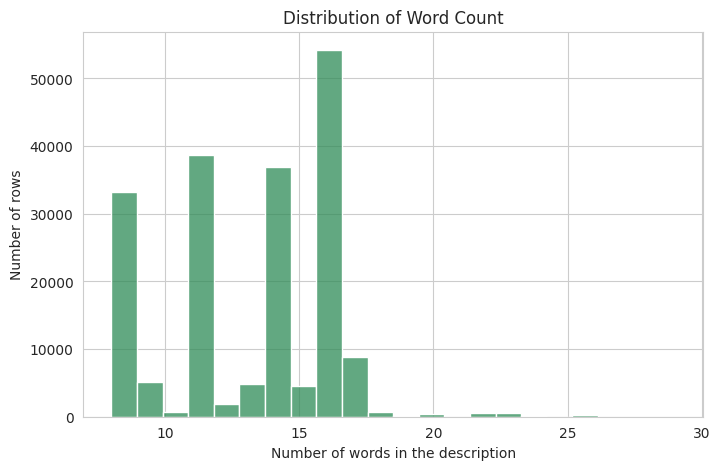

In [27]:
plt.figure(figsize=(8, 5))
sns.histplot(df["Word Count"], bins=22, color="seagreen")
plt.title("Distribution of Word Count")
plt.xlabel("Number of words in the description")
plt.ylabel("Number of rows")
plt.show()

**What does this chart show?** Most descriptions have between 10 and 17 words. The shape is very similar to the character-length chart, which makes sense because more words usually means more characters.

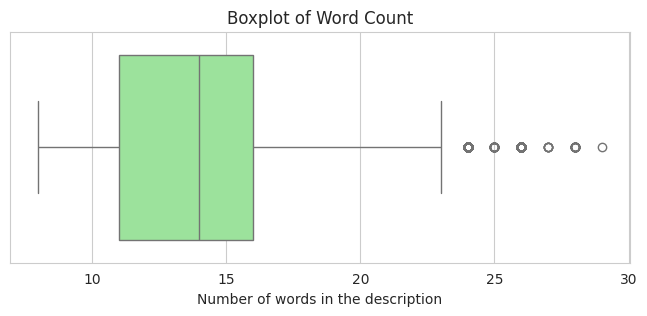

In [28]:
plt.figure(figsize=(8, 3))
sns.boxplot(x=df["Word Count"], color="lightgreen")
plt.title("Boxplot of Word Count")
plt.xlabel("Number of words in the description")
plt.show()

**What does this chart show?** The typical description has about 11 to 16 words (median 14). A few long sentences with more than 23 words appear as dots on the right.

### 10.3 Interaction Type (categorical)

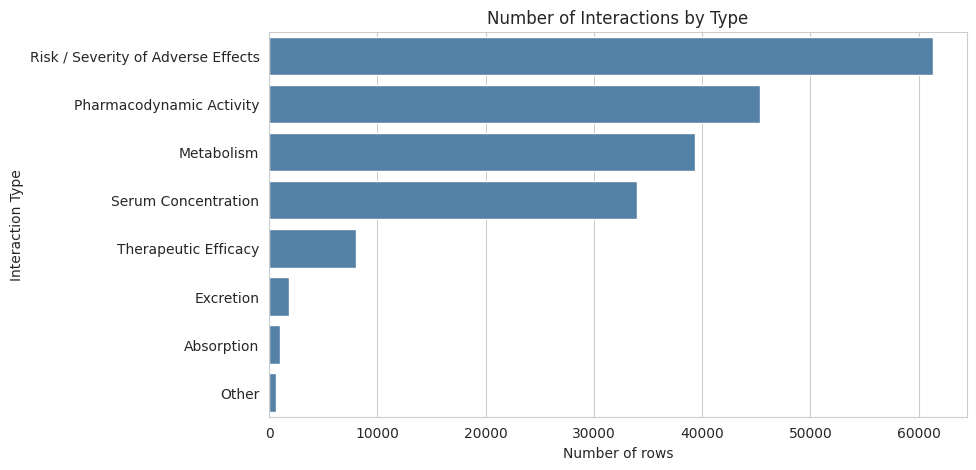

In [29]:
plt.figure(figsize=(9, 5))
order = df["Interaction Type"].value_counts().index
sns.countplot(y="Interaction Type", data=df, order=order, color="steelblue")
plt.title("Number of Interactions by Type")
plt.xlabel("Number of rows")
plt.ylabel("Interaction Type")
plt.show()

**What does this chart show?** Four types (Risk / Severity, Pharmacodynamic Activity, Metabolism, Serum Concentration) make up almost 94% of the dataset. Excretion, Absorption and Other are very small groups.

### 10.4 Effect (categorical)

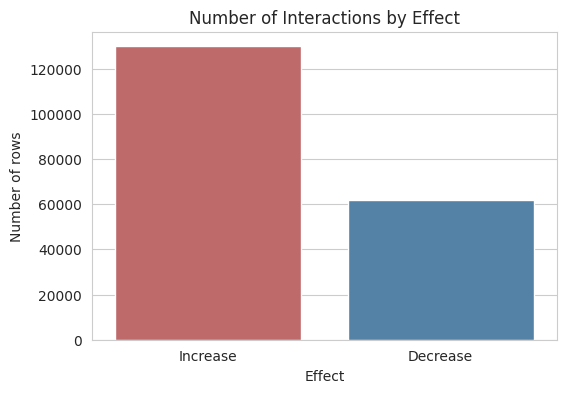

In [30]:
plt.figure(figsize=(6, 4))
sns.countplot(x="Effect", data=df, order=["Increase", "Decrease"], palette=["indianred", "steelblue"], hue="Effect", legend=False)
plt.title("Number of Interactions by Effect")
plt.xlabel("Effect")
plt.ylabel("Number of rows")
plt.show()

**What does this chart show?** "Increase" appears about twice as often as "Decrease".

### 10.5 Most frequent drugs (categorical)

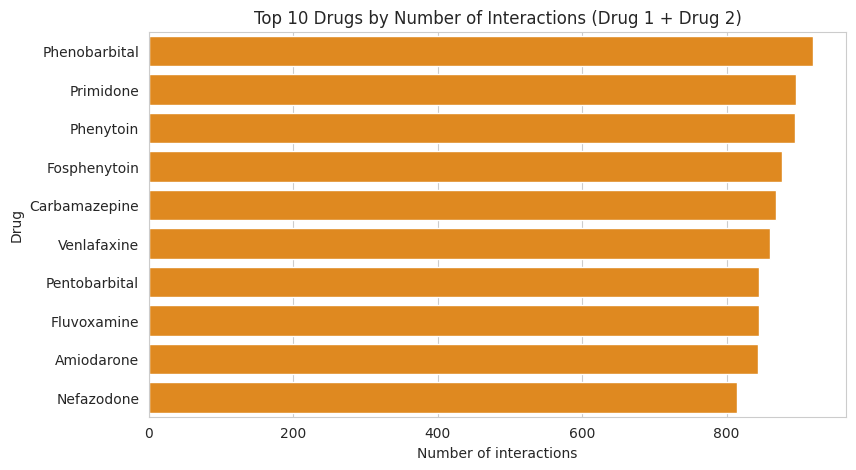

In [31]:
top10 = drug_counts.head(10)

plt.figure(figsize=(9, 5))
sns.barplot(x=top10.values, y=top10.index, color="darkorange")
plt.title("Top 10 Drugs by Number of Interactions (Drug 1 + Drug 2)")
plt.xlabel("Number of interactions")
plt.ylabel("Drug")
plt.show()

**What does this chart show?** The 10 drugs with the most interactions each appear in about 800 to 920 rows. Phenobarbital is first. The differences among these 10 are small.

### 10.6 How many interactions does each drug have?

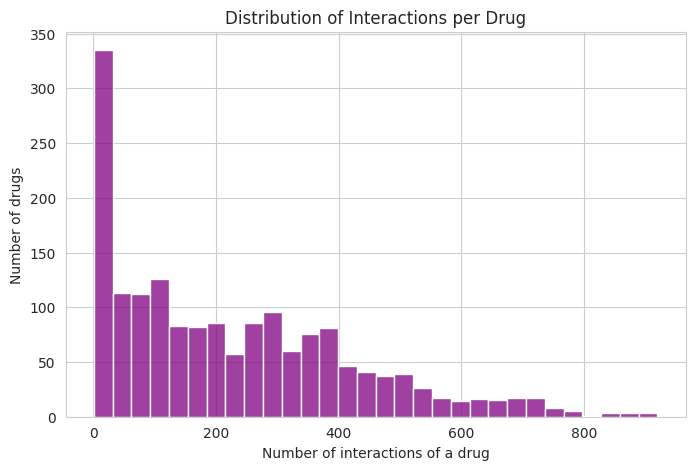

Average interactions per drug : 225.2
Median interactions per drug  : 184.0
Maximum                       : 920
Drugs appearing only once     : 68


In [32]:
plt.figure(figsize=(8, 5))
sns.histplot(drug_counts, bins=30, color="purple")
plt.title("Distribution of Interactions per Drug")
plt.xlabel("Number of interactions of a drug")
plt.ylabel("Number of drugs")
plt.show()

print("Average interactions per drug :", round(drug_counts.mean(), 1))
print("Median interactions per drug  :", drug_counts.median())
print("Maximum                       :", drug_counts.max())
print("Drugs appearing only once     :", (drug_counts == 1).sum())

**What does this chart show?** Drugs are very **unequal**. Many drugs have only a few interactions, while some have hundreds. The average is about 225 interactions per drug, but the median is 184, and 68 drugs appear only once.

# 11. Outlier Analysis

**What is an outlier?** An outlier is a value that is much bigger or much smaller than most of the other values. In a boxplot it is shown as a dot outside the "whiskers".

We use the **IQR rule**: a value is an outlier if it is larger than `Q3 + 1.5 × IQR` or smaller than `Q1 − 1.5 × IQR`, where `IQR = Q3 − Q1`.

We check the numeric columns (`Description Length`, `Word Count`) and the number of interactions per drug.

**Expected output:** the outlier limits and counts, plus one boxplot for the drug counts.

In [33]:
# IQR rule for the numeric columns
for column in ["Description Length", "Word Count"]:
    q1 = df[column].quantile(0.25)
    q3 = df[column].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    low_outliers = (df[column] < lower).sum()
    high_outliers = (df[column] > upper).sum()

    print(column)
    print("  Lower limit:", lower, "| Upper limit:", upper)
    print("  Outliers below:", low_outliers, "| Outliers above:", high_outliers)
    print()

Description Length
  Lower limit: 37.0 | Upper limit: 141.0
  Outliers below: 0 | Outliers above: 1601

Word Count
  Lower limit: 3.5 | Upper limit: 23.5
  Outliers below: 0 | Outliers above: 499



Interactions per drug -> upper limit: 793.0
Drugs above the upper limit: 11


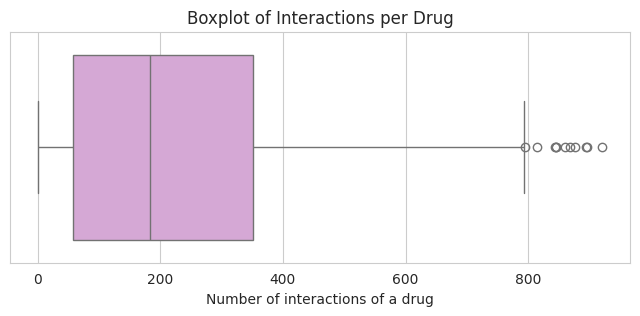

In [34]:
# Same rule for the number of interactions per drug
q1 = drug_counts.quantile(0.25)
q3 = drug_counts.quantile(0.75)
iqr = q3 - q1
upper_drugs = q3 + 1.5 * iqr

print("Interactions per drug -> upper limit:", upper_drugs)
print("Drugs above the upper limit:", (drug_counts > upper_drugs).sum())

plt.figure(figsize=(8, 3))
sns.boxplot(x=drug_counts, color="plum")
plt.title("Boxplot of Interactions per Drug")
plt.xlabel("Number of interactions of a drug")
plt.show()

In [35]:
# Look at the longest descriptions to see if they are real
df.sort_values("Description Length", ascending=False)[["Interaction Description", "Description Length"]].head(3)

,Interaction Description,Description Length
59760,The serum concentration of the active metaboli...,195
59761,The serum concentration of the active metaboli...,193
87272,The serum concentration of the active metaboli...,191


**What does this mean? Should we remove the outliers?**

- There are **no low outliers**. There are a number of **high** outliers in `Description Length` and `Word Count`: sentences that are much longer than usual.
- Looking at the longest descriptions, they are **normal, complete sentences** (for example *"...the active metabolites of ... can be reduced when ... resulting in a loss in efficacy"*). They are simply more detailed, so they are **real values, not errors**.
- Among drugs, **11 drugs** have far more interactions than the others (more than 793 each). This is also **real**: some drugs interact with many other drugs.

**Decision: we keep all outliers.** Removing them would delete real information (for example whole groups of long Absorption/Serum-concentration descriptions and the most heavily interacting drugs). Also, we are not using these numbers in a model yet.

# 12. Bivariate Analysis

Bivariate analysis studies the relationship between **two variables**.

We compare:

1. `Interaction Type` vs `Effect` (categorical + categorical)
2. `Interaction Type` vs `Description Length` (categorical + numeric)
3. `Effect` vs `Description Length` (categorical + numeric)
4. `Description Length` vs `Word Count` (numeric + numeric)
5. Top 10 drugs vs `Interaction Type` (categorical + categorical)

Remember: a relationship does **not** mean one variable *causes* the other.

### 12.1 Interaction Type vs Effect

In [36]:
# Crosstab (counts)
pd.crosstab(df["Interaction Type"], df["Effect"])

Effect,Decrease,Increase
Interaction Type,,
Absorption,938,82
Excretion,1824,32
Metabolism,34313,5000
Other,562,38
Pharmacodynamic Activity,6516,38823
Risk / Severity of Adverse Effects,0,61370
Serum Concentration,9726,24293
Therapeutic Efficacy,7780,244


In [37]:
# Crosstab in percentages (each row adds up to 100%)
(pd.crosstab(df["Interaction Type"], df["Effect"], normalize="index") * 100).round(1)

Effect,Decrease,Increase
Interaction Type,,
Absorption,92.0,8.0
Excretion,98.3,1.7
Metabolism,87.3,12.7
Other,93.7,6.3
Pharmacodynamic Activity,14.4,85.6
Risk / Severity of Adverse Effects,0.0,100.0
Serum Concentration,28.6,71.4
Therapeutic Efficacy,97.0,3.0


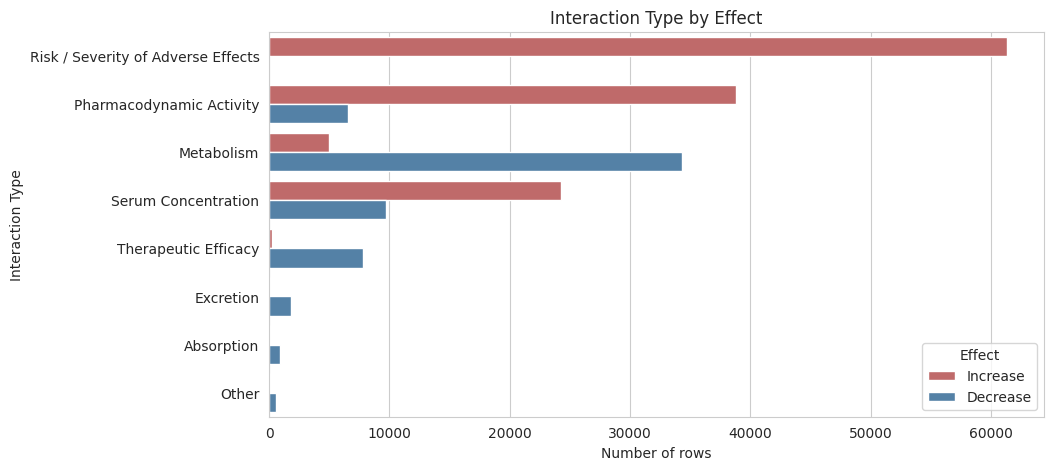

In [38]:
plt.figure(figsize=(10, 5))
order = df["Interaction Type"].value_counts().index
sns.countplot(y="Interaction Type", hue="Effect", data=df, order=order,
              hue_order=["Increase", "Decrease"], palette=["indianred", "steelblue"])
plt.title("Interaction Type by Effect")
plt.xlabel("Number of rows")
plt.ylabel("Interaction Type")
plt.legend(title="Effect")
plt.show()

**What are we comparing?** The type of interaction and whether the effect is an increase or a decrease.

**What pattern do we see?** There is a **strong relationship**:

- *Risk / Severity of Adverse Effects* is **100% Increase** (the risk or severity is always increased).
- *Pharmacodynamic Activity* is mostly **Increase** (about 86%).
- *Serum Concentration* is mostly Increase (about 71%).
- *Metabolism* is mostly **Decrease** (about 87%), and *Therapeutic Efficacy*, *Excretion* and *Absorption* are also mostly Decrease.

**Important note:** part of this pattern comes from how the sentences are written and how we built the labels, so it describes the wording in the dataset. It does not prove anything about cause and effect.

### 12.2 Interaction Type vs Description Length

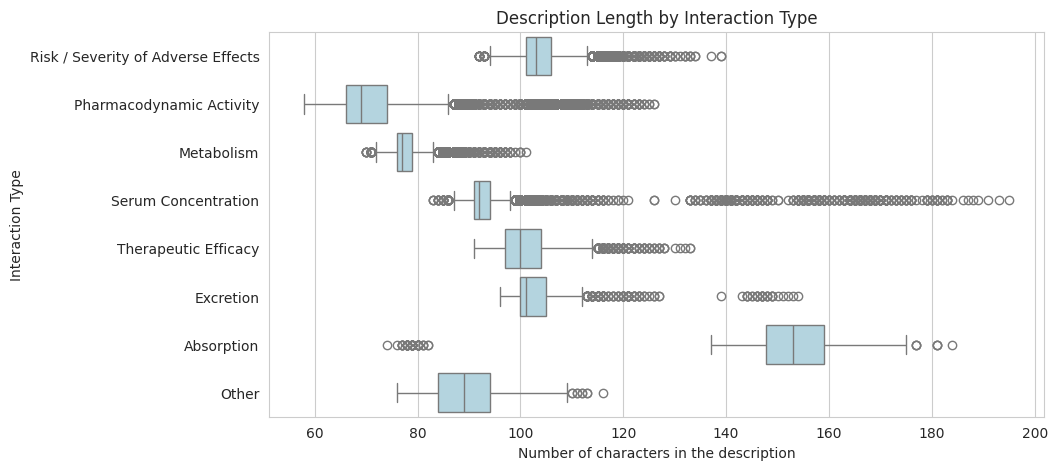

In [39]:
plt.figure(figsize=(10, 5))
order = df["Interaction Type"].value_counts().index
sns.boxplot(y="Interaction Type", x="Description Length", data=df, order=order, color="lightblue")
plt.title("Description Length by Interaction Type")
plt.xlabel("Number of characters in the description")
plt.ylabel("Interaction Type")
plt.show()

**What are we comparing?** The sentence length for each interaction type.

**What pattern do we see?** Sentence length changes a lot between types. *Absorption* sentences are the longest (median about 153 characters), while *Pharmacodynamic Activity* (median about 69) and *Metabolism* (median about 77) are the shortest. *Risk / Severity*, *Therapeutic Efficacy* and *Excretion* are around 100 characters. So the type is related to the length, but this is mainly because each type uses a different sentence template.

### 12.3 Effect vs Description Length

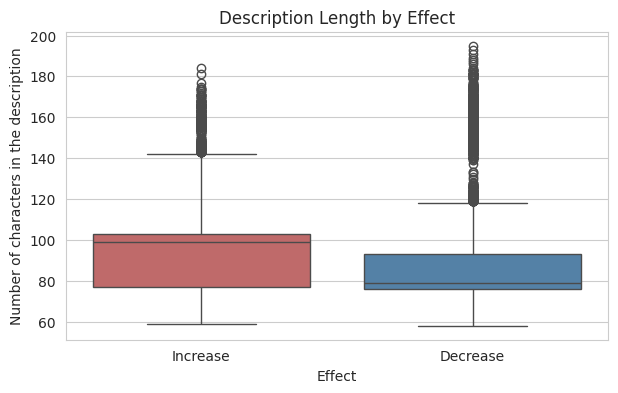

In [40]:
plt.figure(figsize=(7, 4))
sns.boxplot(x="Effect", y="Description Length", data=df, order=["Increase", "Decrease"],
            palette=["indianred", "steelblue"], hue="Effect", legend=False)
plt.title("Description Length by Effect")
plt.xlabel("Effect")
plt.ylabel("Number of characters in the description")
plt.show()

**What are we comparing?** The sentence length for "Increase" and "Decrease" rows.

**What pattern do we see?** "Increase" descriptions are slightly longer on average (about 92 characters) than "Decrease" descriptions (about 85). The difference is small and the boxes overlap a lot, so there is **only a weak relationship**.

### 12.4 Description Length vs Word Count

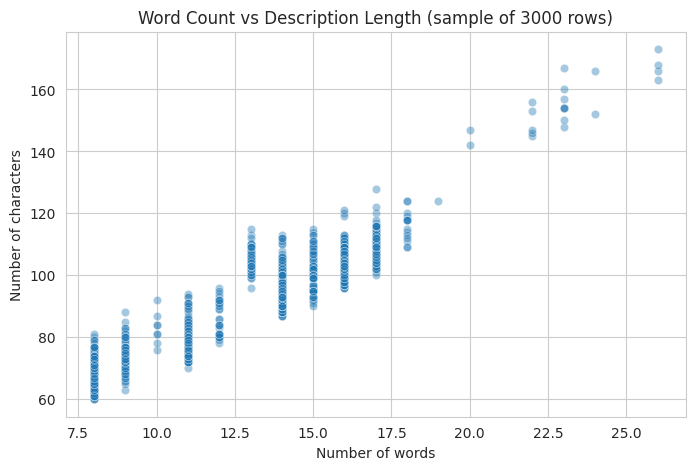

In [41]:
# Use a random sample of 3000 rows so the chart is fast and readable
sample = df.sample(3000, random_state=42)

plt.figure(figsize=(8, 5))
sns.scatterplot(x="Word Count", y="Description Length", data=sample, alpha=0.4)
plt.title("Word Count vs Description Length (sample of 3000 rows)")
plt.xlabel("Number of words")
plt.ylabel("Number of characters")
plt.show()

**What are we comparing?** The number of words and the number of characters in the same sentence.

**What pattern do we see?** A clear **positive** pattern: the more words, the more characters. This is expected because both are measured from the same sentence, so it is not a surprising finding.

### 12.5 Top 10 drugs vs Interaction Type

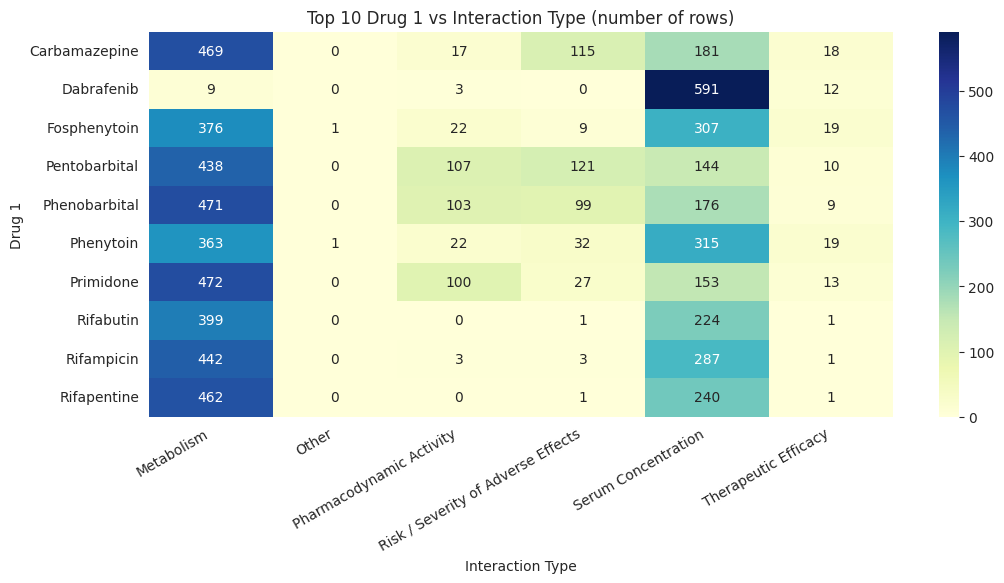

In [42]:
# Take the 10 most frequent drugs in Drug 1 and see which interaction types they have
top10_drug1 = df["Drug 1"].value_counts().head(10).index
subset = df[df["Drug 1"].isin(top10_drug1)]

table = pd.crosstab(subset["Drug 1"], subset["Interaction Type"])

plt.figure(figsize=(12, 5))
sns.heatmap(table, annot=True, fmt="d", cmap="YlGnBu")
plt.title("Top 10 Drug 1 vs Interaction Type (number of rows)")
plt.xlabel("Interaction Type")
plt.ylabel("Drug 1")
plt.xticks(rotation=30, ha="right")
plt.show()

**What are we comparing?** For the drugs that most often appear as `Drug 1`, which interaction types do they have?

**What pattern do we see?** For 9 of these 10 drugs the largest group is **Metabolism** (Phenobarbital, for example, has 471 Metabolism rows), and Serum Concentration is usually second. The exception is **Dabrafenib**, which is almost entirely Serum Concentration (591 rows). So the busiest drugs are mainly linked to Metabolism or Serum Concentration interactions in this dataset.

### 12.6 Important relationships (summary)

The most meaningful relationships we found in this dataset:

1. **Interaction Type ↔ Effect:** very strong (Risk/Severity is always "Increase"; Metabolism is mostly "Decrease").
2. **Interaction Type ↔ Description Length:** clear, because each type uses a different sentence style (Absorption is longest).
3. **Drug ↔ Interaction Type:** the drugs with the most interactions are mostly connected to Metabolism-type sentences (Dabrafenib is the exception: mostly Serum Concentration).
4. **Effect ↔ Description Length:** weak.

Other relationships (like age, price or date) are **not applicable because the dataset does not contain the required type of variable.**

# 13. Correlation Analysis

Correlation measures how two **numeric** variables move together, from **-1** to **+1**.

- **Positive** correlation: when one goes up, the other tends to go up.
- **Negative** correlation: when one goes up, the other tends to go down.
- Near **0** means weak; near **±1** means strong.

The original dataset has no numeric columns, so we can only use the two columns we created (`Description Length` and `Word Count`).

**Expected output:** a 2×2 correlation table and a heatmap.

In [43]:
corr = df.corr(numeric_only=True)
corr.round(3)

,Description Length,Word Count
Description Length,1.000,0.946
Word Count,0.946,1.000


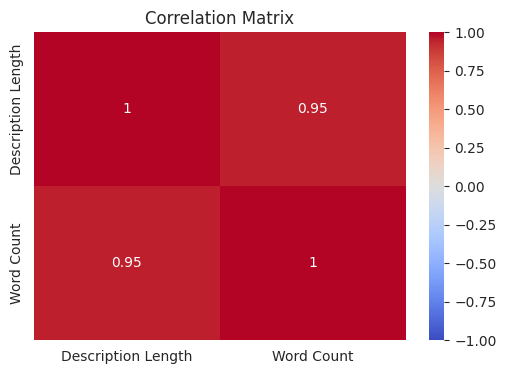

In [44]:
plt.figure(figsize=(6, 4))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation Matrix")
plt.show()

**What does this mean?** The correlation between `Description Length` and `Word Count` is about **0.95**, which is a **strong positive** correlation. This is expected because both numbers come from the same sentence, so it does not teach us anything new about drugs.

Since there are only two numeric columns and both were created by us, a larger correlation analysis is **not applicable because the dataset does not contain enough original numeric variables**. Also, correlation does **not** mean causation.

# 14. Groupby Analysis

We use simple `groupby` to answer 5 questions, and then a short **Top / Bottom analysis**.

**Expected output:** small tables.

### Question 1: How many interactions are in each type, and how long are their descriptions?

In [45]:
df.groupby("Interaction Type")["Description Length"].agg(["count", "mean", "median", "max"]).round(1).sort_values("count", ascending=False)

,count,mean,median,max
Interaction Type,,,,
Risk / Severity of Adverse Effects,61370,103.8,103.0,139
Pharmacodynamic Activity,45339,74.1,69.0,126
Metabolism,39313,77.9,77.0,101
Serum Concentration,34019,94.4,92.0,195
Therapeutic Efficacy,8024,101.2,100.0,133
Excretion,1856,103.6,101.0,154
Absorption,1020,151.2,153.0,184
Other,600,90.1,89.0,116


**Meaning:** Risk / Severity has the most rows (61,370). Absorption has the longest descriptions on average (about 151 characters) and Pharmacodynamic Activity the shortest (about 74).

### Question 2: Which `Drug 1` has the most interactions?

In [46]:
df.groupby("Drug 1")["Drug 2"].count().sort_values(ascending=False).head(10)

Drug 1
Phenobarbital    858
Pentobarbital    820
Carbamazepine    800
Primidone        765
Phenytoin        752
Rifampicin       736
Fosphenytoin     734
Rifapentine      704
Rifabutin        625
Dabrafenib       615
Name: Drug 2, dtype: int64

**Meaning:** Phenobarbital (858), Pentobarbital (820), Carbamazepine (800), Primidone (765) and Phenytoin (752) lead the `Drug 1` column.

### Question 3: Which `Drug 2` has the most interactions?

In [47]:
df.groupby("Drug 2")["Drug 1"].count().sort_values(ascending=False).head(10)

Drug 2
Stiripentol     736
Ketoconazole    684
Fluvoxamine     677
Nefazodone      668
Clotrimazole    653
Indinavir       651
Mifepristone    648
Clemastine      646
Ticlopidine     642
Venlafaxine     639
Name: Drug 1, dtype: int64

**Meaning:** In the `Drug 2` column the leaders are different: Stiripentol (736), Ketoconazole (684), Fluvoxamine (677), Nefazodone (668) and Clotrimazole (653). This shows that some drugs appear mostly as the *first* drug and others mostly as the *second* drug.

### Question 4: With how many different partner drugs does each `Drug 1` interact?

In [48]:
df.groupby("Drug 1")["Drug 2"].nunique().sort_values(ascending=False).head(10)

Drug 1
Phenobarbital    850
Pentobarbital    812
Carbamazepine    790
Primidone        757
Phenytoin        745
Rifampicin       730
Fosphenytoin     727
Rifapentine      696
Rifabutin        617
Dabrafenib       615
Name: Drug 2, dtype: int64

**Meaning:** This counts *different* partner drugs (not repeated rows). The top drugs interact with hundreds of different partners. It is very close to the row counts because most drug pairs appear only once.

### Question 5: Are "Increase" descriptions longer than "Decrease" descriptions?

In [49]:
df.groupby("Effect")["Description Length"].mean().round(1)

Effect
Decrease    84.7
Increase    92.3
Name: Description Length, dtype: float64

**Meaning:** "Increase" descriptions average about 92.3 characters and "Decrease" about 84.7. There is a small difference only.

### Top / Bottom analysis

In [50]:
print("Top 10 most frequent drugs (Drug 1 + Drug 2):")
print(drug_counts.head(10))
print()

print("Bottom 10 drugs (fewest interactions):")
print(drug_counts.tail(10))
print()

print("Most frequent interaction types:")
print(df["Interaction Type"].value_counts().head(3))
print()

print("Least frequent interaction types:")
print(df["Interaction Type"].value_counts().tail(3))

Top 10 most frequent drugs (Drug 1 + Drug 2):
Phenobarbital    920
Primidone        896
Phenytoin        895
Fosphenytoin     877
Carbamazepine    868
Venlafaxine      860
Pentobarbital    845
Fluvoxamine      845
Amiodarone       844
Nefazodone       815
Name: count, dtype: int64

Bottom 10 drugs (fewest interactions):
Oseltamivir             1
Nonoxynol-9             1
Regadenoson             1
Phendimetrazine         1
Acetohydroxamic acid    1
Trimetazidine           1
Benzoctamine            1
Captodiame              1
Cloxazolam              1
Lactulose               1
Name: count, dtype: int64

Most frequent interaction types:
Interaction Type
Risk / Severity of Adverse Effects    61370
Pharmacodynamic Activity              45339
Metabolism                            39313
Name: count, dtype: int64

Least frequent interaction types:
Interaction Type
Excretion     1856
Absorption    1020
Other          600
Name: count, dtype: int64


In [51]:
# Longest and shortest descriptions
print("Longest descriptions:")
print(df.sort_values("Description Length", ascending=False)[["Interaction Description", "Description Length"]].head(3).to_string())
print()
print("Shortest descriptions:")
print(df.sort_values("Description Length", ascending=True)[["Interaction Description", "Description Length"]].head(3).to_string())

Longest descriptions:
                                                                                                                                                                                   Interaction Description  Description Length
59760  The serum concentration of the active metabolites of Mycophenolic acid can be reduced when Mycophenolic acid is used in combination with Procaine benzylpenicillin resulting in a loss in efficacy.                 195
59761    The serum concentration of the active metabolites of Mycophenolic acid can be reduced when Mycophenolic acid is used in combination with Phenoxymethylpenicillin resulting in a loss in efficacy.                 193
87272      The serum concentration of the active metabolites of Dabigatran etexilate can be reduced when Dabigatran etexilate is used in combination with Dexlansoprazole resulting in a loss in efficacy.                 191

Shortest descriptions:
                                          Interaction Descript

**Meaning:** Phenobarbital, Primidone and Phenytoin have the most interactions overall, while the bottom drugs have only **one** interaction each. The shortest sentences are short template sentences (for example *"X may increase the bradycardic activities of Digoxin."*), and the longest sentences are detailed sentences about active metabolites.

*Price, quantity, category-value and status analyses: This analysis is not applicable because the dataset does not contain the required type of variable.*

# 15. Key Insights

All insights below come from the results above.

1. **Size and structure:** the dataset has **191,541 rows** and 3 text columns (`Drug 1`, `Drug 2`, `Interaction Description`). There are no original numeric or date columns.
2. **Very clean data:** there are **no missing values**, **no exact duplicate rows** and **no extra spaces** in the text.
3. **Many different drugs:** there are **1,701 different drugs**. 1,634 appear in `Drug 1` and 1,606 in `Drug 2`.
4. **Most common interaction type:** *Risk / Severity of Adverse Effects* (**32%**), followed by *Pharmacodynamic Activity* (24%), *Metabolism* (21%) and *Serum Concentration* (18%). Together these four types are about 94% of the data.
5. **More "increase" than "decrease":** about **68%** of the descriptions talk about an increase and **32%** about a decrease.
6. **Type and effect are strongly linked:** Risk / Severity is always an increase, Metabolism is mostly a decrease (about 87%), and Therapeutic Efficacy is mostly a decrease (about 97%).
7. **Unequal drugs:** the average drug has about **225** interactions but the median is **184**, and the busiest drug (**Phenobarbital**) has **920**. **68 drugs** appear only once.
8. **Description length:** the average description is about **90 characters (13 words)**, ranging from 58 to 195 characters. Absorption descriptions are the longest (about 151 characters on average).
9. **Outliers are real:** the 1,601 long descriptions (over 141 characters) are normal detailed sentences, and 11 drugs have unusually many interactions (over 793). We **kept** them all.
10. **Repeated pairs are not errors:** 289 rows repeat an existing `Drug 1` + `Drug 2` pair, and 117 drug pairs appear in both orders, but they describe different effects, so we kept them.

**Limitation:** `Interaction Type` and `Effect` were created by simple keyword rules, so they are an approximation of the real meaning of each sentence.

# 16. Final Data Quality Summary

**Expected output:** one summary table.

In [52]:
rows_after = df.shape[0]

# Outliers for Description Length (IQR rule again)
q1 = df["Description Length"].quantile(0.25)
q3 = df["Description Length"].quantile(0.75)
upper = q3 + 1.5 * (q3 - q1)
length_outliers = (df["Description Length"] > upper).sum()

summary = pd.DataFrame({
    "Item": [
        "Rows before cleaning",
        "Rows after cleaning",
        "Exact duplicate rows removed",
        "Rows repeating the same Drug 1 + Drug 2 pair (kept)",
        "Missing values (total)",
        "Data type corrections needed",
        "Text corrections needed (extra spaces / capitalization)",
        "New columns created",
        "Long-description outliers found (kept)",
        "Different drugs in the dataset"
    ],
    "Result": [
        rows_before,
        rows_after,
        rows_before - rows_after,
        df.duplicated(subset=["Drug 1", "Drug 2"]).sum(),
        df[["Drug 1", "Drug 2", "Interaction Description"]].isnull().sum().sum(),
        "None (all text columns are correct as text)",
        "None (no extra spaces; drug names kept in original capitalization)",
        "4 (Description Length, Word Count, Interaction Type, Effect)",
        length_outliers,
        len(drug_counts)
    ]
})

summary

,Item,Result
0,Rows before cleaning,191541
1,Rows after cleaning,191541
2,Exact duplicate rows removed,0
3,Rows repeating the same Drug 1 + Drug 2 pair (...,289
4,Missing values (total),0
5,Data type corrections needed,None (all text columns are correct as text)
6,Text corrections needed (extra spaces / capita...,None (no extra spaces; drug names kept in orig...
7,New columns created,"4 (Description Length, Word Count, Interaction..."
8,Long-description outliers found (kept),1601
9,Different drugs in the dataset,1701


**Important observations:**

- The original data was already clean: **no missing values, no duplicate rows, and no wrong data types**.
- No rows were removed, so the number of rows before and after cleaning is the same.
- Outliers exist but they are real values, so they were kept.
- Drug names should **not** be changed to title case or upper case because names such as `gamma-Hydroxybutyric acid` have a specific correct spelling.

# 17. Save Clean Dataset

We save the cleaned DataFrame (with the 4 new columns) to a new CSV file and check that the file was created.

**Expected output:** a message that the file exists and a preview of its first rows.

In [53]:
# Save without the index column
df.to_csv("cleaned_data.csv", index=False)

# Verify that the file was created
print("File created:", os.path.exists("cleaned_data.csv"))

# Read it back to check
check = pd.read_csv("cleaned_data.csv")
print("Shape of saved file:", check.shape)
check.head()

File created: True


Shape of saved file: (191541, 7)


,Drug 1,Drug 2,Interaction Description,Description Length,Word Count,Interaction Type,Effect
0,Trioxsalen,Verteporfin,Trioxsalen may increase the photosensitizing a...,71,8,Pharmacodynamic Activity,Increase
1,Aminolevulinic acid,Verteporfin,Aminolevulinic acid may increase the photosens...,80,9,Pharmacodynamic Activity,Increase
2,Titanium dioxide,Verteporfin,Titanium dioxide may increase the photosensiti...,77,9,Pharmacodynamic Activity,Increase
3,Tiaprofenic acid,Verteporfin,Tiaprofenic acid may increase the photosensiti...,77,9,Pharmacodynamic Activity,Increase
4,Cyamemazine,Verteporfin,Cyamemazine may increase the photosensitizing ...,72,8,Pharmacodynamic Activity,Increase


**What does this mean?** The file `cleaned_data.csv` was created with the same number of rows as the original and 7 columns (3 original + 4 new). It is ready for the next step of the project.

---
**End of the EDA notebook.**